<a href="https://colab.research.google.com/github/RafaelNovais/MasterAI/blob/master/Heart_failure_patient_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import json
import os
import warnings
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_samples,
                             silhouette_score)
from sklearn.preprocessing import StandardScaler


## 1. load

In [5]:
SEED = 42
np.random.seed(SEED)
os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"font.size": 8, "axes.titlesize": 9, "axes.labelsize": 8,
                     "figure.dpi": 150, "axes.spines.top": False,
                     "axes.spines.right": False})

raw = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Heart_failure_data.csv")
FEATURES = ["age", "anaemia", "creatinine_phosphokinase", "diabetes",
            "ejection_fraction", "high_blood_pressure", "platelets",
            "serum_creatinine", "serum_sodium", "sex", "smoking"]
BINARY = ["anaemia", "diabetes", "high_blood_pressure", "sex", "smoking"]
CONT = [f for f in FEATURES if f not in BINARY]

# the clustering and used afterwards to sanity-check the clusters.
X = raw[FEATURES].copy()
res = {"n_rows": len(raw), "missing": raw[FEATURES + ["time"]].isna().sum().to_dict(),
       "missing_total_cells": int(X.isna().sum().sum()),
       "rows_with_any_missing": int(X.isna().any(axis=1).sum())}

# pre-existing placeholder values (mean-imputed upstream)
res["placeholders"] = {
    "platelets==263358.03": int((raw.platelets.round(2) == 263358.03).sum()),
    "serum_creatinine==1.83": int((raw.serum_creatinine == 1.83).sum()),
    "serum_creatinine==1.18": int((raw.serum_creatinine == 1.18).sum()),
    "age==60.667": int((raw.age == 60.667).sum()),
}
res["skew_before"] = X[CONT].skew().round(2).to_dict()

## 2. pre-process

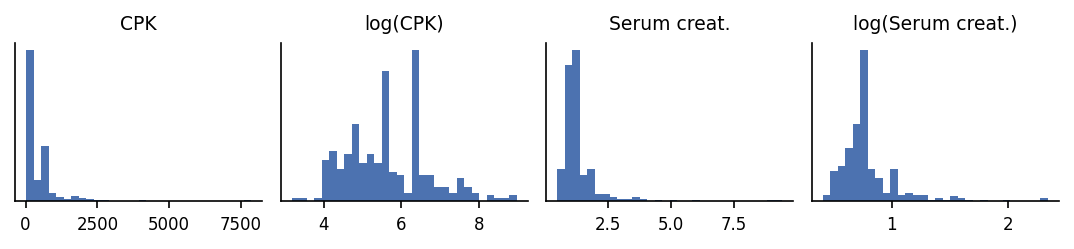

In [6]:
# robust to skew / outliers / most frequent category / heavy right tails
Xt = Xi.copy()
Xi = X.copy()
for c in CONT:
    Xi[c] = Xi[c].fillna(Xi[c].median())
for c in BINARY:
    Xi[c] = Xi[c].fillna(Xi[c].mode()[0])
for c in ["creatinine_phosphokinase", "serum_creatinine"]:
    Xt[c] = np.log1p(Xt[c])
res["skew_after"] = Xt[CONT].skew().round(2).to_dict()
Z = StandardScaler().fit_transform(Xt)
Zdf = pd.DataFrame(Z, columns=FEATURES)

# figure
fig, ax = plt.subplots(1, 4, figsize=(7.2, 1.7))
for a, (c, lab) in zip(ax, [("creatinine_phosphokinase", "CPK"),
                            ("creatinine_phosphokinase", "log(CPK)"),
                            ("serum_creatinine", "Serum creat."),
                            ("serum_creatinine", "log(Serum creat.)")]):
    d = Xi[c] if not lab.startswith("log") else Xt[c]
    a.hist(d, bins=30, color="#4c72b0")
    a.set_title(lab)
    a.set_yticks([])
plt.tight_layout()
plt.savefig("figures/skew.png")
plt.show()

## 3. choose k

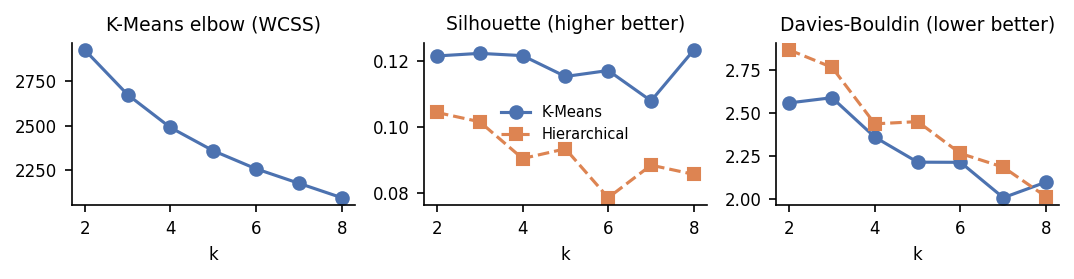

In [7]:
# K-Means
ks = range(2, 9)
sel = {"k": list(ks), "km_wcss": [], "km_sil": [], "km_db": [], "hc_sil": [], "hc_db": []}
for k in ks:
    km = KMeans(k, n_init=50, random_state=SEED).fit(Z)
    hc = AgglomerativeClustering(k, linkage="ward").fit(Z)
    sel["km_wcss"].append(km.inertia_)
    sel["km_sil"].append(silhouette_score(Z, km.labels_))
    sel["km_db"].append(davies_bouldin_score(Z, km.labels_))
    sel["hc_sil"].append(silhouette_score(Z, hc.labels_))
    sel["hc_db"].append(davies_bouldin_score(Z, hc.labels_))
res["k_selection"] = {k: [round(float(x), 4) for x in v] for k, v in sel.items()}

fig, ax = plt.subplots(1, 3, figsize=(7.2, 1.9))
ax[0].plot(sel["k"], sel["km_wcss"], "o-", color="#4c72b0")
ax[0].set(title="K-Means elbow (WCSS)", xlabel="k")
ax[1].plot(sel["k"], sel["km_sil"], "o-", label="K-Means", color="#4c72b0")
ax[1].plot(sel["k"], sel["hc_sil"], "s--", label="Hierarchical", color="#dd8452")
ax[1].set(title="Silhouette (higher better)", xlabel="k")
ax[1].legend(frameon=False, fontsize=7)
ax[2].plot(sel["k"], sel["km_db"], "o-", color="#4c72b0")
ax[2].plot(sel["k"], sel["hc_db"], "s--", color="#dd8452")
ax[2].set(title="Davies-Bouldin (lower better)", xlabel="k")
plt.tight_layout()
plt.savefig("figures/k_selection.png")
plt.show()

## 4. final models

In [8]:
# align hierarchical labels to K-Means
K = int(os.environ.get("K", 3))
km = KMeans(K, n_init=100, random_state=SEED).fit(Z)
Zl = linkage(Z, "ward")
hc = AgglomerativeClustering(K, linkage="ward").fit(Z)


def order_by_risk(labels):
    """Relabel clusters 0..K-1 by ascending mean serum creatinine (stable naming)."""
    m = pd.Series(Xi["serum_creatinine"].values).groupby(labels).mean().sort_values()
    mp = {old: new for new, old in enumerate(m.index)}
    return np.array([mp[l] for l in labels])


lab_km = order_by_risk(km.labels_)
lab_hc = order_by_risk(hc.labels_)

ct = pd.crosstab(lab_km, lab_hc)
res["crosstab_km_rows_hc_cols"] = ct.values.tolist()

metrics = {}
for name, lab in [("K-Means", lab_km), ("Hierarchical (Ward)", lab_hc)]:
    wcss = sum(((Z[lab == c] - Z[lab == c].mean(0)) ** 2).sum() for c in np.unique(lab))
    metrics[name] = {"silhouette": silhouette_score(Z, lab),
                     "davies_bouldin": davies_bouldin_score(Z, lab),
                     "calinski_harabasz": calinski_harabasz_score(Z, lab),
                     "wcss": wcss,
                     "sizes": np.bincount(lab).tolist()}
res["metrics"] = metrics
res["ARI_km_vs_hc"] = adjusted_rand_score(lab_km, lab_hc)


rng = np.random.default_rng(SEED)
stab = {"K-Means": [], "Hierarchical (Ward)": []}
for _ in range(100):
    idx = rng.choice(len(Z), len(Z), replace=True)
    kmb = KMeans(K, n_init=10, random_state=SEED).fit(Z[idx])
    hcb = AgglomerativeClustering(K, linkage="ward").fit(Z[idx])
    stab["K-Means"].append(adjusted_rand_score(lab_km, kmb.predict(Z)))

    stab["Hierarchical (Ward)"].append(adjusted_rand_score(lab_hc[idx], hcb.labels_))
    stab["K-Means"][-1] = adjusted_rand_score(lab_km[idx], kmb.labels_)
res["stability_ARI_mean"] = {k: round(float(np.mean(v)), 3) for k, v in stab.items()}
res["stability_ARI_sd"] = {k: round(float(np.std(v)), 3) for k, v in stab.items()}

## 5. visuals

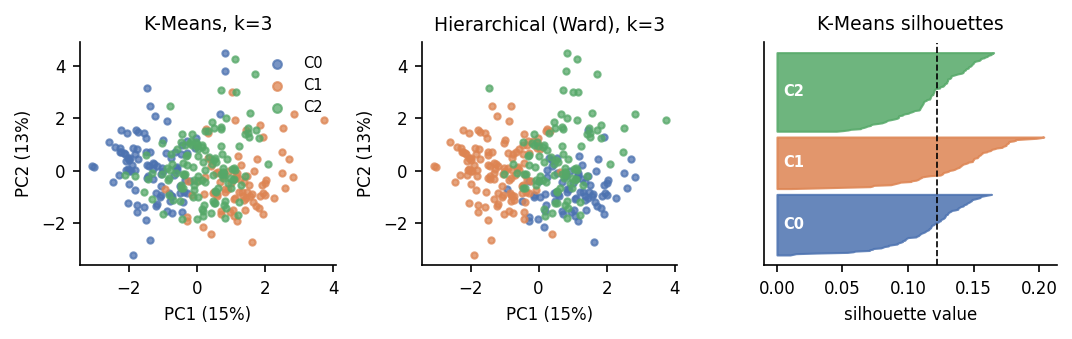

In [9]:
# plot (K-Means)
pca = PCA(2, random_state=SEED).fit(Z)
P = pca.transform(Z)
res["pca_var"] = pca.explained_variance_ratio_.round(3).tolist()
res["pca_loadings"] = pd.DataFrame(pca.components_.T, index=FEATURES,
                                   columns=["PC1", "PC2"]).round(2).to_dict()
pal = ["#4c72b0", "#dd8452", "#55a868", "#c44e52", "#8172b3"]

fig, ax = plt.subplots(1, 3, figsize=(7.2, 2.3), gridspec_kw={"width_ratios": [1, 1, 1.15]})
for a, lab, ttl in [(ax[0], lab_km, "K-Means"), (ax[1], lab_hc, "Hierarchical (Ward)")]:
    for c in range(K):
        a.scatter(P[lab == c, 0], P[lab == c, 1], s=9, alpha=.75, color=pal[c], label=f"C{c}")
    a.set(title=f"{ttl}, k={K}", xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%})",
          ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
ax[0].legend(frameon=False, fontsize=7, markerscale=1.4)

sv = silhouette_samples(Z, lab_km)
y0 = 0
for c in range(K):
    s = np.sort(sv[lab_km == c])
    ax[2].fill_betweenx(np.arange(y0, y0 + len(s)), 0, s, color=pal[c], alpha=.85)
    ax[2].text(0.005, y0 + len(s) / 2, f"C{c}", fontsize=7, va="center", color="white",
               fontweight="bold")
    y0 += len(s) + 8
ax[2].axvline(sv.mean(), color="k", ls="--", lw=.8)
ax[2].set(title="K-Means silhouettes", xlabel="silhouette value", yticks=[])
plt.tight_layout()
plt.savefig("figures/scatter.png")
plt.show()

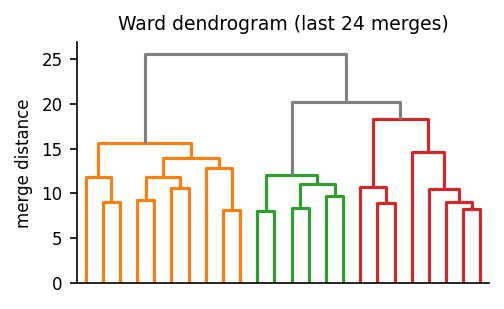

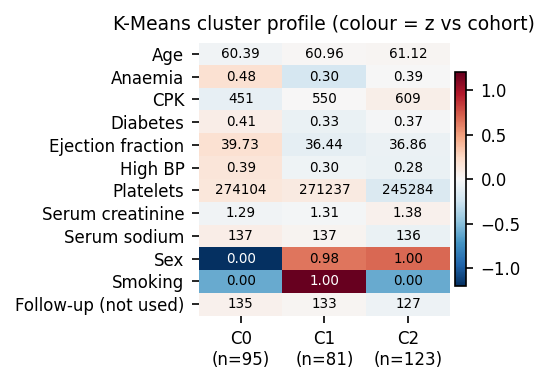

In [10]:
fig, ax = plt.subplots(figsize=(3.4, 2.1))
dendrogram(Zl, truncate_mode="lastp", p=24, no_labels=True, ax=ax,
           color_threshold=Zl[-(K - 1), 2] - 1e-6, above_threshold_color="grey")
ax.set(title="Ward dendrogram (last 24 merges)", ylabel="merge distance")
plt.tight_layout()
plt.savefig("figures/dendrogram.png")
plt.show()

# profile heat-map
prof = Xi.assign(c=lab_km).groupby("c").mean()
prof["time"] = raw["time"].groupby(lab_km).mean()
res["profile_km"] = prof.round(2).to_dict("index")
res["profile_km_size_pct"] = (np.bincount(lab_km) / len(lab_km) * 100).round(1).tolist()
zprof = (prof - Xi.assign(time=raw["time"]).mean()) / Xi.assign(time=raw["time"]).std()
fig, ax = plt.subplots(figsize=(3.6, 2.6))
im = ax.imshow(zprof.T.values, cmap="RdBu_r", vmin=-1.2, vmax=1.2, aspect="auto")
ax.set_xticks(range(K), [f"C{c}\n(n={n})" for c, n in enumerate(np.bincount(lab_km))])
nice = {"creatinine_phosphokinase": "CPK", "ejection_fraction": "Ejection fraction",
        "high_blood_pressure": "High BP", "serum_creatinine": "Serum creatinine",
        "serum_sodium": "Serum sodium", "time": "Follow-up (not used)"}
ax.set_yticks(range(len(zprof.columns)), [nice.get(c, c.capitalize()) for c in zprof.columns])
for i in range(zprof.shape[1]):
    for j in range(K):
        v = prof.iloc[j, i]
        ax.text(j, i, f"{v:.0f}" if abs(v) >= 100 else f"{v:.2f}", ha="center",
                va="center", fontsize=6.5, color="white" if abs(zprof.iloc[j, i]) > .8 else "black")
ax.spines[:].set_visible(False)
ax.set_title("K-Means cluster profile (colour = z vs cohort)")
plt.colorbar(im, ax=ax, fraction=.04, pad=.02)
plt.tight_layout()
plt.savefig("figures/profile.png")
plt.show()

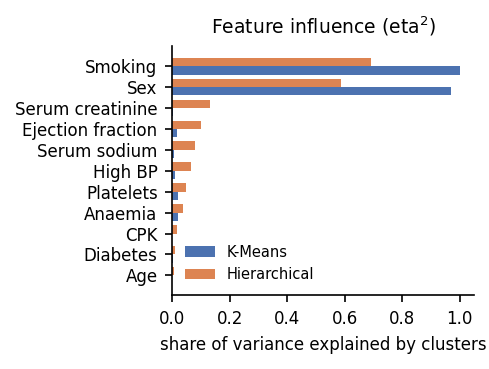

In [13]:
# hierarchical profile too
prof_h = Xi.assign(c=lab_hc).groupby("c").mean()
res["profile_hc"] = prof_h.round(2).to_dict("index")

#K-Means cluster
clin = pd.DataFrame({
    "n": np.bincount(lab_km),
    "EF<40% (%)": [(Xi.ejection_fraction[lab_km == c] < 40).mean() * 100 for c in range(K)],
    "creat>1.5 (%)": [(Xi.serum_creatinine[lab_km == c] > 1.5).mean() * 100 for c in range(K)],
    "Na<135 (%)": [(Xi.serum_sodium[lab_km == c] < 135).mean() * 100 for c in range(K)],
}).round(1)
res["clinical_rates_km"] = clin.to_dict("index")


def eta2(lab):
    return {f: float(1 - sum(((Zdf[f][lab == c] - Zdf[f][lab == c].mean()) ** 2).sum()
                          for c in range(K)) / ((Zdf[f] - Zdf[f].mean()) ** 2).sum())
            for f in FEATURES}


e_km, e_hc = eta2(lab_km), eta2(lab_hc)
res["eta2_km"] = {k: round(v, 3) for k, v in e_km.items()}
res["eta2_hc"] = {k: round(v, 3) for k, v in e_hc.items()}
order = sorted(FEATURES, key=lambda f: e_km[f] + e_hc[f])
fig, ax = plt.subplots(figsize=(3.3, 2.5))
yy = np.arange(len(order))
ax.barh(yy - .2, [e_km[f] for f in order], .4, color="#4c72b0", label="K-Means")
ax.barh(yy + .2, [e_hc[f] for f in order], .4, color="#dd8452", label="Hierarchical")
ax.set_yticks(yy, [nice.get(f, f.capitalize()) for f in order])
ax.set(title="Feature influence (eta$^2$)", xlabel="share of variance explained by clusters")
ax.legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.savefig("figures/influence.png")
plt.show()


Zc = Zdf[CONT].values
sens = {}
for k in (2, 3):
    a = KMeans(k, n_init=100, random_state=SEED).fit(Zc).labels_
    b = AgglomerativeClustering(k, linkage="ward").fit(Zc).labels_
    sens[k] = {"km_sil": silhouette_score(Zc, a), "hc_sil": silhouette_score(Zc, b),
               "km_db": davies_bouldin_score(Zc, a), "hc_db": davies_bouldin_score(Zc, b),
               "ARI": adjusted_rand_score(a, b)}
res["sensitivity_continuous_only"] = sens


a3 = KMeans(3, n_init=100, random_state=SEED).fit(Zc).labels_
res["ARI_cont_vs_full_km"] = adjusted_rand_score(a3, lab_km)
res["ARI_cont_vs_full_hc"] = adjusted_rand_score(a3, lab_hc)

clin_h = pd.DataFrame({
    "n": np.bincount(lab_hc),
    "EF<40% (%)": [(Xi.ejection_fraction[lab_hc == c] < 40).mean() * 100 for c in range(K)],
    "creat>1.5 (%)": [(Xi.serum_creatinine[lab_hc == c] > 1.5).mean() * 100 for c in range(K)],
    "Na<135 (%)": [(Xi.serum_sodium[lab_hc == c] < 135).mean() * 100 for c in range(K)],
    "follow-up (d)": [raw.time[lab_hc == c].mean() for c in range(K)],
}).round(1)
res["clinical_rates_hc"] = clin_h.to_dict("index")

